# Figure 6: T-S Space LSSW-mSW

## Import Packages

In [1]:
import pandas as pd
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, zoomed_inset_axes
import matplotlib.ticker as mticker
from matplotlib import path
from matplotlib.colors import TwoSlopeNorm
import matplotlib.cm as cm
from matplotlib.patches import Polygon
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import datetime
import math
from scipy.ndimage import gaussian_filter

import xarray as xr
from netCDF4 import Dataset
from xgcm import Grid
import cmaps
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os
import glob

import rioxarray

from dask.diagnostics import ProgressBar

from scipy.ndimage import gaussian_filter1d

from pyproj import Transformer

import seawater as sw
import gsw

import calendar

import pickle

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/sitecustomize.py:72: UserWarning: The seawater library is deprecated! Please use gsw instead.
  mod = _real_import(name, globals, locals, fromlist, level)


## Import Data

In [2]:
# ---------- OBSERVATIONAL DATA ----------
ROOT = '/g/data/gv90/ad6790/amery-amisor'
os.chdir(f'{ROOT}/notebooks')

from fun_filtering import lowpass_filter

df = pd.read_parquet(f'{ROOT}/data/proc/04_filtered.parquet')

# ---------- NEUTRAL DENSITY CURVES ----------
# Load in the neutral density contours as determined by Blanckensee et al. (2024)
with open("/g/data/gv90/ad6790/amery-amisor/data/external/SiennaNeve-CDObs-203a48c/Notebooks/neu_dens_contours.pkl", "rb") as f: 
    nd_contours = pickle.load(f)
x_curve1 = nd_contours["x_curve1"]  # 28.27 contour
y_curve1 = nd_contours["y_curve1"]
x_curve2 = nd_contours["x_curve2"]  # 28.00 contour
y_curve2 = nd_contours["y_curve2"]

## Define Resuable Functions

In [3]:
# Define a function to label the neutral density curves tangentially
def label_curve_tangent(ax, x_curve, y_curve, fraction, text, color, fontsize, **kwargs):
    n = len(x_curve)
    # Define an index for the anchor point based on the length of the curve and the fractional distance along it
    idx = int(fraction * (n - 1))
    # Define the anchor point
    anchor_point = (x_curve[idx], y_curve[idx])

    # Pick points neighbouring the anchoring point to estimate the tangent
    i0 = max(idx - 1, 0)
    i1 = min(idx + 1, n - 1)

    # Convert these points to display coordinates so the angle accounts of the axis scaling
    p0 = ax.transData.transform((x_curve[i0], y_curve[i0]))
    p1 = ax.transData.transform((x_curve[i1], y_curve[i1]))
    # Calculate the change in display in display coordinates in the x and y directions
    dx_display = p1[0] - p0[0] 
    dy_display = p1[1] - p0[1] 

    # Calculate the angle of the slope 
    angle = np.degrees(np.arctan2(dy_display, dx_display))
    
    # Find a perpendicular unit vector in display coordinates to create a buffer between the curve and the label 
    length = np.hypot(dx_display, dy_display)
    perp_x = -dy_display / length
    perp_y = dx_display / length

    # Find the anchor point and the offset point from here in display coordinates
    anchor_display = ax.transData.transform(anchor_point)
    offset_display = (anchor_display[0] + 10 * perp_x, anchor_display[1] + 10 * perp_y)

    # Convert this offset point back into data coordinates to be able to plot it correctly
    offset_point = ax.transData.inverted().transform(offset_display)

    # Check if the anchor point falls within the plot's visible area and if it doesn't we ignore this label
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    if not (xlim[0] <= anchor_point[0] <= xlim[1] and ylim[0] <= anchor_point[1] <= ylim[1]):
        return 

    ax.text(offset_point[0], offset_point[1], text, rotation=angle, rotation_mode="anchor", ha="center", va="center", color=color, fontsize=fontsize, **kwargs)

# Trim a T-S curve so it starts on the 0 dbar freezing line rather than running below it
def clip_to_freezing(x, y):
    """Keep only the part of a T-S curve at or above the surface freezing point."""
    d = y - gsw.CT_freezing(x, 0, 0)
    keep = d >= 0
    if not keep.any():
        return x[keep], y[keep]
    i = np.argmax(keep)                       # first point above freezing
    if i == 0:
        return x[keep], y[keep]
    # Linear interpolation between the last point below and the first above, so the
    # curve begins exactly on the freezing line instead of jumping to the next sample
    f = -d[i-1] / (d[i] - d[i-1])
    x0 = x[i-1] + f * (x[i] - x[i-1])
    y0 = y[i-1] + f * (y[i] - y[i-1])
    return np.concatenate([[x0], x[keep]]), np.concatenate([[y0], y[keep]])

# 95% highest-density band: the contour of the smoothed 2-D histogram that encloses BAND_FRAC of the points.
# Sparse outliers fall outside it; separate dense clusters each get their own closed contour.
def density_band(ax, salt, temp, colour, zorder=4):
    # Convert temp and salinity data into plain numpy arrays of floats
    salt = np.asarray(salt, dtype=float)
    temp = np.asarray(temp, dtype=float)

    # Define a boolean for where both salinity and temp are not NaN (i.e. points we can use)
    real_value = np.isfinite(salt) & np.isfinite(temp)
    
    # Skip if there are not enough real numbers
    if real_value.sum() < 20:
        return

    # Divide the visible plot area into a grid of boxes (e.g., 200 x 200 = 40,000) and count the number of points in each box
    # H = counts, xe and ye = box edges (201 each)
    H, x_edge, y_edge = np.histogram2d(salt[real_value], temp[real_value], bins=BAND_BINS, range=[xlim_sal, ylim_temp])

    # Since a grid of boxes would look ragged, we replace each count with a weighted average of counts around it
    # Weights follow a bell curve centred on that box => BAND_SMOOTH is the width (std dev) of that bell
    H = gaussian_filter(H, BAND_SMOOTH)
    
    # If no points fell inside the axis limit there's nothing to draw and we ignore
    if H.sum() == 0:
        return

    # Flatten grid into one long list of 40,000 box values, sort, and reverse so densest box is first
    h = np.sort(H.ravel())[::-1]

    # Add boxes from densest to sparsest until they collectively/cumulatively hold 95% of the points
    # level = density of the last box added (density threshold)
    level = h[min(np.searchsorted(np.cumsum(h) / h.sum(), BAND_FRAC), h.size - 1)]

    # Ignore cases where the density of the last box added is 0 (enclose empty space) or maximum (encloses nothing)
    if level <= 0 or level >= H.max():
        return

    # Average pairs of neighbouring edges to get the centre between them
    x_centre = 0.5 * (x_edge[1:] + x_edge[:-1])
    y_centre = 0.5 * (y_edge[1:] + y_edge[:-1])

    # Draw the ling where smoothed density equals the threshold => the boundary of the 95% region
    ax.contour(x_centre, y_centre, H.T, levels=[level], colors=[colour], linewidths=1.2, zorder=zorder)

## Plots
### Define Constant and Common Variables

In [4]:
# Define a dictionary mapping each MicroCAT to it's pre-calculated average pressure
# Average pressure is the mean pressure on deployment
AVG_PRESSURES = {
    "1969": 441.1,    "1970": 581.6,   "1971": 743.4,
    "1623": 338.5,    "1624": 562.7,   "1174": 770.2,
    "4055": 661.4,    "4054": 872.2,   "3883": 1227.1,
    "1972": 550.4,    "1973": 693.0,   "1974": 814.7,
    "7327": 580.5,    "7326": 738.8,   "7322": 876.6,
    "7325": 551.4,    "7324": 680.8,   "7323": 790.3,
}



# Colours assigned to boreholes in month mode (when multiple boreholes are shown)
BOREHOLE_COLOURS = {
    "AM01": {"1969": "darkgreen", "1970": "forestgreen", "1971": "mediumseagreen"},
    "AM02": {"1623": "darkred", "1624": "red", "1174": "indianred"},
    "AM03": {"4055": "saddlebrown", "4054": "sandybrown", "3883": "peru"},
    "AM04": {"1972": "black", "1973": "grey", "1974": "darkgrey"},
    "AM05": {"7327": "indigo", "7326": "darkviolet", "7322": "mediumorchid"},
    "AM06": {"7325": "navy", "7324": "royalblue", "7323": "cornflowerblue"},
}

POSITION_INDEX = {"upper": 0, "middle": 1, "lower": 2}

# Define a colourmap for the water column of model data
cmap = 'cmo.deep'
# Create a linear mapping of depth from 0 to 1 using the approximated shallowest and deepest levels (in metres) from across all borehole locations in the model 
norm = mcolors.Normalize(vmin=200, vmax=1300)

# Define the limits of the y-axes for plots of temperature and salinity
ylim_temp = (-2.299, -1.701)
xlim_sal = (34.501, 34.799)

# Define the limits of the y-axes for plots of temperature and salinity
ylim_temp = (-2.399, -1.601)
xlim_sal = (34.451, 34.799)

FS_MAIN = 12     # panel titles, axis labels, instrument labels
FS_SMALL = 12    # tick labels, including the month letters

plt.rcParams.update({
    "font.size": FS_MAIN,
    "axes.titlesize": FS_MAIN,
    "axes.labelsize": FS_MAIN,
    "xtick.labelsize": FS_SMALL,
    "ytick.labelsize": FS_SMALL,
    "legend.fontsize": FS_SMALL,
})

obsv_kw = dict(s=2)
freeze_kw = dict(color="blue", linestyle="-", lw=0.8, label="_", zorder=4)
isopycnal_kw = dict(colors="black", linestyles="-", linewidths=0.6, alpha=0.2, zorder=1)
neutral_kw = dict(color="red", linestyle="-", lw=1.5, zorder=4)
gade_kw = dict(color="k", linestyle="--", lw=1.5, label="_", zorder=5)
curve_label_kwargs = dict(zorder=6)
label_kw = dict(fontsize=FS_SMALL)
legend_kw = dict(ncol=1, frameon=False, markerscale=2)

## Figure 6: T-S Space LSSW-mSW

In [5]:
# MicroCATs to plot, as (borehole, MicroCAT) - all go on the same panels
cats = [("AM02", "1624"), ("AM03", "4055")]
# 

# Years whose raw data are plotted as points
years = [2001, 2006]

# Marker for particular years
YEAR_MARKERS = {2001: "x", 2003: "x"}

LEGEND_ENTRIES = [("AM02", "1624", 2001), ("AM02", "1624", 2006), ("AM03", "4055", 2006)]

# Define the months to be plotted
months = [2, 5, 7, 9]
# months = [6, 8, 10]

# Initialise a list of salinity values corresponding to the source water mass at ~-1.9C
meltwater_mixing_lines = [34.62, 34.67]

# Band settings: histogram resolution over the axis range, and Gaussian smoothing (in bins)
# Lower BAND_SMOOTH if nearby clusters merge; raise it if bands look ragged/fragmented
BAND_BINS = 200
BAND_SMOOTH = 2.0
BAND_FRAC = 0.95

612.05
612.05
612.05
612.05


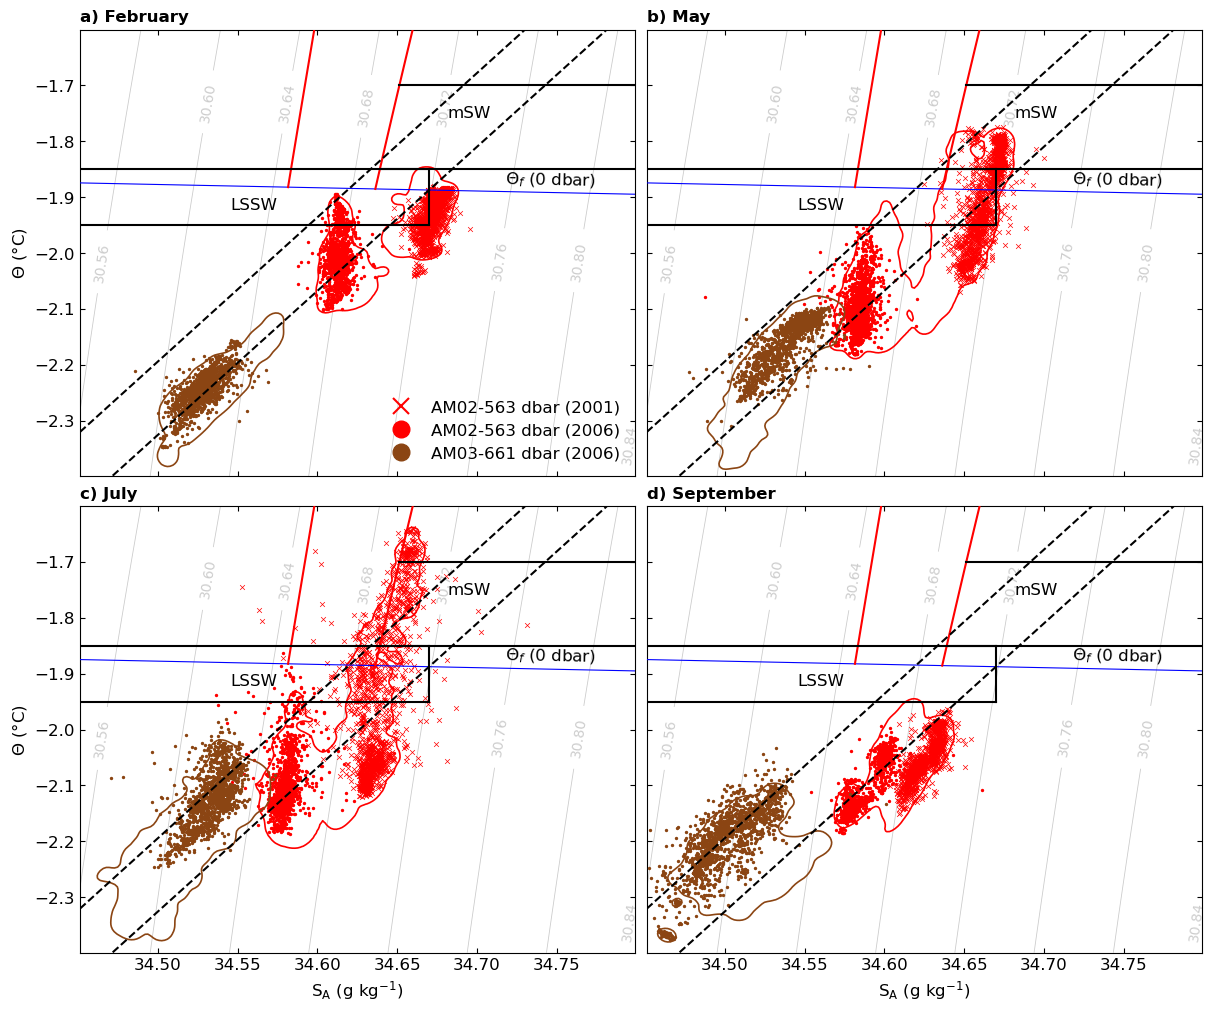

In [7]:
columns = 2
rows = math.ceil(len(months) / columns)

fig, axes = plt.subplots(rows, columns, figsize=(6 * columns, 5 * rows), sharex=True, sharey=True, layout='constrained', squeeze=False)
axes_flat = axes.flatten()

# Define the range of temp and salinity over which to plot overlays
salinity_range = np.linspace(xlim_sal[0], xlim_sal[1], 100)
temp_range = np.linspace(ylim_temp[0], ylim_temp[1], 100)

panel_labels = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm']

for i, month in enumerate(months):
    # Create a new subplot for this month
    ax = axes_flat[i]
    ax.set_xlim(*xlim_sal)
    ax.set_ylim(*ylim_temp)

    ax.set_title(f"{panel_labels[i]}) " + pd.Timestamp(2001, month, 1).strftime("%B"), loc='left', fontweight="bold")
    
    # -- PLOT OBSERVATIONAL DATA --
    for borehole, cat in cats:
        # Create a mask to filter the dataframe for the specified borehole and cat, in this month
        mask = (df["borehole"] == borehole) & (df["cat"] == cat) & (df["time"].dt.month == month)
        sub = df[mask]

                # Raw points for the chosen years only (borehole colour)
        # >>> CHANGED: one year at a time, with that year's marker
        for year in years:
            in_year = sub[sub["time"].dt.year == year]
            ax.scatter(in_year["absolute_salinity"], in_year["conservative_temperature"], c=BOREHOLE_COLOURS[borehole][cat], marker=YEAR_MARKERS.get(year, "o"), linewidths=0.5 if year in YEAR_MARKERS else None, label="_", zorder=3, s=12 if year in YEAR_MARKERS else obsv_kw["s"])
        
        # Raw points for the chosen years only (borehole colour)
        # in_years = sub[sub["time"].dt.year.isin(years)]
        # ax.scatter(in_years["absolute_salinity"], in_years["conservative_temperature"], c=BOREHOLE_COLOURS[borehole][cat], label="_", zorder=3, **obsv_kw)

        # 95% band around all years of raw data for this MicroCAT in this month (borehole colour, outline only, drawn over the points)
        density_band(ax, sub["absolute_salinity"].values, sub["conservative_temperature"].values, BOREHOLE_COLOURS[borehole][cat])

    if i == 0:
        for borehole, cat, year in LEGEND_ENTRIES:
            ax.plot([], [], color=BOREHOLE_COLOURS[borehole][cat], marker=YEAR_MARKERS.get(year, "o"), markeredgewidth=1.5 if year in YEAR_MARKERS else None, linestyle="none", label=f"{borehole}-{AVG_PRESSURES[cat]:.0f} dbar ({year})")

    # -- PLOT OVERLAYS --
    # - Freezing point temperature line at 0 dbar (saturation fraction = 0) -
    CT_freeze_0 = gsw.CT_freezing(salinity_range, 0, 0)
    ax.plot(salinity_range, CT_freeze_0, **freeze_kw)
    label_curve_tangent(ax, salinity_range, CT_freeze_0, 0.85, r"$\Theta_f$ (0 dbar)", "black", FS_SMALL, **curve_label_kwargs)

    # - Isopycnals (potential density anomaly contours) referenced to the average pressure of the plot MicroCATs
    # Reference pressure for the potential density anomaly (dbar)
    pressures = []
    for borehole, cat in cats:
        pressures.append(AVG_PRESSURES[cat])
    reference_pressure = np.mean(pressures)
    print(reference_pressure)
    
    salinity_grid, temp_grid = np.meshgrid(salinity_range, temp_range)
    sigma = gsw.rho(salinity_grid, temp_grid, reference_pressure) - 1000
    cs = ax.contour(salinity_grid, temp_grid, sigma, **isopycnal_kw)
    ax.clabel(cs, inline=True, fontsize=10, fmt="%.2f")

    # - Neutral density curves from Blanckensee et al. (2024) -
    xc1, yc1 = clip_to_freezing(np.asarray(x_curve1), np.asarray(y_curve1))
    xc2, yc2 = clip_to_freezing(np.asarray(x_curve2), np.asarray(y_curve2))
    ax.plot(xc1, yc1, **neutral_kw)
    ax.plot(xc2, yc2, **neutral_kw)
    # label_curve_tangent(ax, xc2, yc2, 0.03, "28.00", "black", 10, **curve_label_kwargs)
    # label_curve_tangent(ax, xc1, yc1, 0.03, "28.27", "black", 10, **curve_label_kwargs)

    # - Meltwater mixing line using gsw (equation 16 from McDougall et al. (2014)) -
    # First, assume "the temperature of the glacial ice, -15 C, measured from a thermistor cable at AM01" as per Herraiz-Borreguero et al. (2013) (also used in Silvano et al. (2017))
    t_ice = -15.0

    # REVIEW - WHAT PRESSURE DO WE WANT TO PUT HERE?? (note: slope is not particularly sensitive to this pressure) (2nd note: the slope doesn't seem to change at all regardless of what value we use between 0 and 1000 dbar)
    pressure_source = 550

    # We also need to define conditions of the source water mass - should generally be identified as the warmest/saltiest water mass in the visible datapoints
    for salinity_source in meltwater_mixing_lines:
        # Here, we will define the temp of the source water mass as the surface (0 dbar) freezing point temperature at the given source salinities we have chosen
        temp_source = float(gsw.CT_freezing(salinity_source, 0, 0))
        dSA_dCT = gsw.ice.melting_ice_SA_CT_ratio(salinity_source, temp_source, pressure_source, t_ice)
        slope = 1 / dSA_dCT  # dCT/dSA
        CT_gade = temp_source + slope * (salinity_range - salinity_source)
        ax.plot(salinity_range, CT_gade, **gade_kw)

    # - Low Salinity Shelf Water - 
    # Define after Herraiz-Borreguero et al. (2015) and Rosevear et al. (2022) - -1.95 <= Theta <= -1.85 and S_A > 34.67 g/kg
    lssw_temp = (-1.95, -1.85)
    lssw_sal_max = 34.67
    ax.plot([xlim_sal[0], lssw_sal_max], [lssw_temp[0], lssw_temp[0]], color="black", linestyle="-", lw=1.5, label="_", zorder=4)
    ax.plot([xlim_sal[0], lssw_sal_max], [lssw_temp[1], lssw_temp[1]], color="black", linestyle="-", lw=1.5, label="_", zorder=4)
    ax.plot([lssw_sal_max, lssw_sal_max], [lssw_temp[0], lssw_temp[1]], color="black", linestyle="-", lw=1.5, label="_", zorder=4)
    ax.text(34.575, -1.9, "LSSW", color="black", va="top", ha="right", zorder=2)

        # - modified Shelf Water -
    msw_temp = (-1.85, -1.7)
    # Salinity of the 28.27 curve across the temperature band. The curve rises steadily with temperature,
    # so its salinity can be interpolated at any temperature along it
    t_edge = np.linspace(msw_temp[0], msw_temp[1], 50)
    s_edge = np.interp(t_edge, np.asarray(y_curve1), np.asarray(x_curve1))
    ax.plot([s_edge[0], xlim_sal[1]], [msw_temp[0], msw_temp[0]], color="black", linestyle="-", lw=1.5, label="_", zorder=4)
    ax.plot([s_edge[-1], xlim_sal[1]], [msw_temp[1], msw_temp[1]], color="black", linestyle="-", lw=1.5, label="_", zorder=4)
    ax.text(34.695, msw_temp[1] - 0.05, "mSW", color="black", va="center", ha="center", zorder=2)

# Hide any unused subplots
for j in range(len(months), rows * columns):
    axes_flat[j].axis("off")

for ax in axes_flat:
    ax.tick_params(axis="both", direction="in", top=True, right=True)

# Set the y-axis label for the leftmost plots only
for r in range(rows):
    axes[r, 0].set_ylabel(r"$\Theta$ (°C)", **label_kw)

# Set the x-axis label on the lowest panel in each column (taking into account a last row that isn't full)
for c in range(min(columns, len(months))):
    ax = axes_flat[c + columns * ((len(months) - 1 - c) // columns)]
    ax.set_xlabel(r"$\mathrm{S_{A} \ (g \ kg^{-1})}$", **label_kw)
    # sharex hides tick labels on non-bottom rows — turn them back on here
    ax.tick_params(axis="x", labelbottom=True)

# -- DRAW LEGEND --
axes_flat[0].legend(loc='lower right', **legend_kw)

# fig.savefig('/g/data/gv90/ad6790/amery-amisor/notebooks/figures/ObsT-SLSSW.jpg', format='jpg', dpi=600)
plt.show()